# 08 · G2F: EDA и GBLUP/KBLUP по годам
Конкурс 2024, train-фенотипы 2014–2023. Новый гибрид **внутри того же года**, не прогноз будущего года.
Запуск: **Restart Kernel → Run All**. Сначала поправьте путь в следующей ячейке. Результаты здесь заранее не рассчитаны.

In [2]:
from pathlib import Path
import os
import sys

# Если автоопределение не подходит, укажите корень своего проекта.
PROJECT = None  # например Path(r"D:/work/gp_models")
if PROJECT is None:
    candidates = [Path.cwd(), *Path.cwd().parents]
    PROJECT = next((p for p in candidates if (p / "gp_models/gblup.py").is_file()), None)
if PROJECT is None:
    raise FileNotFoundError("Укажите PROJECT: папку с gp_models/, data/, notebooks/.")
PROJECT = Path(PROJECT).resolve()
sys.path.insert(0, str(PROJECT))

DATA = Path(os.environ.get("G2F_DATA_ROOT", str(PROJECT / "data/G2F/G2F")))
YEARS = list(range(2014, 2024))  # для первого быстрого запуска можно [2019]
SEED, TRAIN_FRAC, N_REPEATS = 42, 0.7, 1
N_THREADS = 2
TARGET = "Yield_Mg_ha"
OUT = PROJECT / "results/g2f_08_v3"
FIG = PROJECT / "figures/g2f_08_v3"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
print("Проект:", PROJECT)
print("Данные:", DATA)

Проект: /mnt/c/Users/User/Desktop/Генотек/Biomni_lab_downloads_20261010_090451/gp_models
Данные: /mnt/c/Users/User/Desktop/Генотек/Biomni_lab_downloads_20261010_090451/gp_models/data/G2F/G2F


In [3]:
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.decomposition import PCA
from threadpoolctl import threadpool_limits
import gp_models
from gp_models.g2f import load_g2f_numeric, regression_metrics
from gp_models.preprocessing import prepare_markers
from gp_models.gblup import prepare_gblup, gblup_fit_reml, gblup_predict
from gp_models.kblup import prepare_kblup, kblup_fit, kblup_predict
from gp_models.cv import random_splits

if Path(gp_models.__file__).resolve().parent.parent != PROJECT:
    raise RuntimeError("Загружен другой gp_models. Restart Kernel и проверьте PROJECT.")
BLAS_LIMIT = threadpool_limits(limits=N_THREADS)
plt.rcParams.update({"font.family": ["Liberation Sans", "Arimo", "DejaVu Sans"],
                     "svg.fonttype": "none", "figure.dpi": 110})
def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", dpi=160, bbox_inches="tight")
    fig.savefig(FIG / f"{name}.svg", bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("Библиотека:", gp_models.__file__)

Библиотека: /mnt/c/Users/User/Desktop/Генотек/Biomni_lab_downloads_20261010_090451/gp_models/gp_models/__init__.py


## 1. Загрузка

In [4]:
TRAIN = DATA / "genomes_to_fields_2024_maize_genotype_by_environment_prediction_competition/Training_data"
PHENO_FILE = TRAIN / "1_Training_Trait_Data_2014_2023.csv"
GENO_FILE = TRAIN / "5_Genotype_Data_All_2014_2025_Hybrids_numerical.txt"
missing_files = [str(p) for p in (PHENO_FILE, GENO_FILE) if not p.is_file()]
if missing_files:
    raise FileNotFoundError("Проверьте DATA/G2F_DATA_ROOT. Отсутствуют:\n" + "\n".join(missing_files))

ph = pd.read_csv(PHENO_FILE, low_memory=False)
required = ["Year", "Env", "Hybrid", "Experiment", "Replicate", "Block", "Plot",
            TARGET, "Plant_Height_cm"]
absent = sorted(set(required) - set(ph.columns))
if absent:
    raise ValueError(f"В таблице отсутствуют столбцы: {absent}")
for col in ["Hybrid", "Env"]:
    ph[col] = ph[col].astype("string").str.strip().replace("", pd.NA)
for col in ["Year", TARGET, "Plant_Height_cm"]:
    ph[col] = pd.to_numeric(ph[col], errors="raise")
    if np.isinf(ph[col].to_numpy(dtype=float)).any():
        raise ValueError(f"Бесконечные значения в {col}")
print("Весь файл:", ph.shape, "; без Year:", ph["Year"].isna().sum())
ph = ph.loc[ph["Year"].isin(YEARS)].copy()
if ph.empty:
    raise ValueError("В выбранных YEARS нет наблюдений.")
ph["Year"] = ph["Year"].astype(int)
geno = load_g2f_numeric(GENO_FILE)  # уже 0/1/2 + NaN, НЕ умножать повторно!
print("Выбранные фенотипы:", ph.shape, "; генотипы:", geno.shape)
display(ph[required].head())

Весь файл: (173960, 26) ; без Year: 0
Выбранные фенотипы: (173960, 26) ; генотипы: (5899, 2425)


,Year,Env,Hybrid,Experiment,Replicate,Block,Plot,Yield_Mg_ha,Plant_Height_cm
0,2014,DEH1_2014,M0088/LH185,G2F_2014_15,1,1,1,5.721725,213.0
1,2014,DEH1_2014,M0143/LH185,G2F_2014_15,1,1,2,11.338246,286.0
2,2014,DEH1_2014,M0003/LH185,G2F_2014_15,1,1,3,6.540810,239.0
3,2014,DEH1_2014,M0035/LH185,G2F_2014_15,1,1,4,10.366857,242.0
4,2014,DEH1_2014,M0052/LH185,G2F_2014_15,1,1,5,10.908814,211.0


## 2. Что есть в каждом году

In [5]:
by_year = ph.groupby("Year").agg(
    n_plots=("Hybrid", "size"), n_envs=("Env", "nunique"),
    n_hybrids=("Hybrid", "nunique"),
    n_yield=(TARGET, "count"), n_height=("Plant_Height_cm", "count"))
by_year["yield_coverage"] = by_year.n_yield / by_year.n_plots
by_year["height_coverage"] = by_year.n_height / by_year.n_plots
by_year.to_csv(OUT / "year_summary.csv")
display(by_year)

trait_summary = ph.groupby("Year")[[TARGET, "Plant_Height_cm"]].describe(
    percentiles=[.05, .25, .5, .75, .95])
trait_summary.columns = [f"{trait}_{stat}" for trait, stat in trait_summary.columns]
trait_summary.to_csv(OUT / "trait_summary.csv")
display(trait_summary.round(2))

,n_plots,n_envs,n_hybrids,n_yield,n_height,yield_coverage,height_coverage
Year,,,,,,,
2014,12675,24,882,11593,11680,0.914635,0.921499
2015,13688,27,1210,13219,11869,0.965736,0.867110
2016,15387,27,645,14452,12840,0.939234,0.834471
2017,15533,30,579,12828,11190,0.825855,0.720402
2018,20851,29,1076,20377,19496,0.977267,0.935015
2019,20806,28,1207,19876,20118,0.955301,0.966933
2020,16940,25,1177,16157,14521,0.953778,0.857202
2021,20132,27,1193,19577,16514,0.972432,0.820286
2022,19084,28,570,18568,16535,0.972962,0.866433


,Yield_Mg_ha_count,Yield_Mg_ha_mean,Yield_Mg_ha_std,Yield_Mg_ha_min,Yield_Mg_ha_5%,Yield_Mg_ha_25%,Yield_Mg_ha_50%,Yield_Mg_ha_75%,Yield_Mg_ha_95%,Yield_Mg_ha_max,Plant_Height_cm_count,Plant_Height_cm_mean,Plant_Height_cm_std,Plant_Height_cm_min,Plant_Height_cm_5%,Plant_Height_cm_25%,Plant_Height_cm_50%,Plant_Height_cm_75%,Plant_Height_cm_95%,Plant_Height_cm_max
Year,,,,,,,,,,,,,,,,,,,,
2014,11593.0,9.19,2.80,0.58,4.14,7.41,9.49,11.16,13.25,21.63,11680.0,217.25,28.67,120.0,170.00,198.00,219.00,238.00,263.0,317.0
2015,13219.0,8.72,2.87,0.68,3.83,6.78,8.78,10.71,13.37,19.54,11869.0,227.19,37.16,120.0,159.00,204.00,231.00,255.00,281.0,342.0
2016,14452.0,8.14,2.77,0.50,2.81,6.44,8.27,10.09,12.34,18.13,12840.0,228.39,37.36,120.0,164.00,202.00,230.00,255.00,287.0,347.0
2017,12828.0,9.69,3.07,0.53,4.12,7.70,10.02,11.88,14.27,20.28,11190.0,225.19,29.46,122.0,174.00,206.00,227.00,246.00,270.0,315.0
2018,20377.0,9.68,2.74,0.62,5.18,7.74,9.76,11.65,14.03,23.27,19496.0,223.16,33.13,120.0,166.00,198.00,226.00,249.00,273.0,327.0
2019,19876.0,11.00,3.00,0.78,5.82,9.00,11.09,13.16,15.72,18.81,20118.0,224.46,30.00,120.0,172.00,202.00,228.00,247.00,269.0,307.0
2020,16157.0,8.98,2.77,0.80,4.44,7.11,8.91,10.85,13.61,18.03,14521.0,233.32,28.19,120.0,185.42,214.00,235.00,253.00,278.0,335.0
2021,19577.0,10.04,2.78,0.58,4.83,8.56,10.32,11.88,14.10,18.77,16514.0,247.01,33.60,120.0,185.00,226.06,248.92,270.00,300.0,350.0
2022,18568.0,9.64,3.61,0.50,2.48,7.30,10.21,12.33,14.71,18.80,16535.0,231.64,34.76,120.0,174.50,206.25,232.50,256.00,290.0,340.0


findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font f

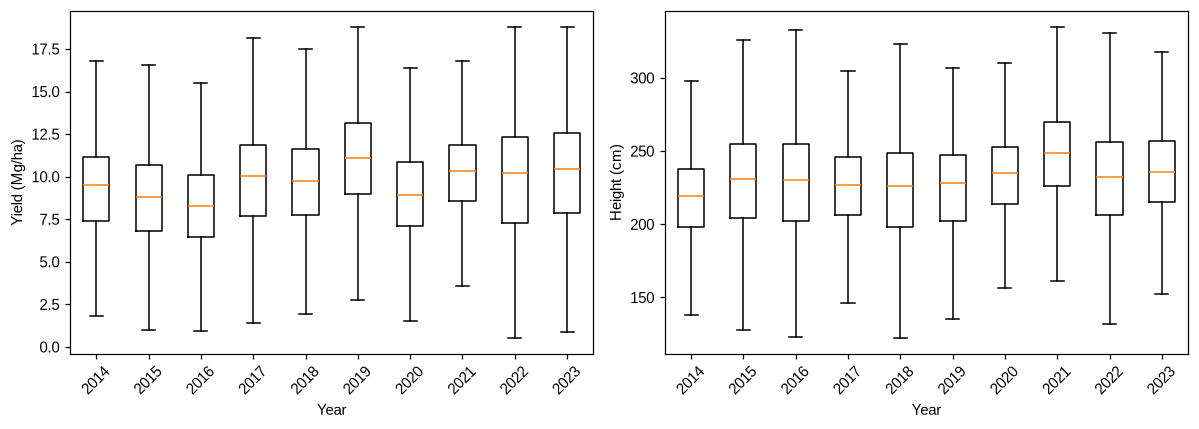

In [6]:
plot_years = sorted(ph.Year.unique())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, trait, label in zip(axes, [TARGET, "Plant_Height_cm"],
                           ["Yield (Mg/ha)", "Height (cm)"]):
    values = [ph.loc[ph.Year.eq(y), trait].dropna().to_numpy() for y in plot_years]
    ax.boxplot(values, showfliers=False)
    ax.set_xticks(range(1, len(plot_years) + 1), plot_years)
    ax.set(xlabel="Year", ylabel=label)
    ax.tick_params(axis="x", rotation=45)
save_figure(fig, "traits_by_year")
# Выбросы скрыты ТОЛЬКО на рисунке; из таблиц и обучения они не удалены.

## 3. Имена, повторы и пропуски

In [7]:
plot_key = ["Env", "Experiment", "Replicate", "Block", "Plot"]
complete_key = ph[plot_key].notna().all(axis=1)
duplicate_rows = complete_key & ph.duplicated(plot_key, keep=False)
ph.loc[duplicate_rows, ["Year", *plot_key, "Hybrid", TARGET]].to_csv(
    OUT / "duplicate_plot_keys.csv", index=False)
ph.loc[~complete_key, ["Year", *plot_key, "Hybrid", TARGET]].to_csv(
    OUT / "incomplete_plot_keys.csv", index=False)
print("Строки с повторным полным ключом:", int(duplicate_rows.sum()))
print("Строки с неполным ключом:", int((~complete_key).sum()))

match = ph[["Year", "Hybrid"]].dropna().drop_duplicates()
match["has_genotype"] = match.Hybrid.isin(geno.index)
match["has_observed_markers"] = match.Hybrid.isin(geno.index[geno.notna().any(axis=1)])
match.to_csv(OUT / "hybrid_matching.csv", index=False)
display(match.groupby("Year").agg(n_hybrids=("Hybrid", "size"),
    n_matched=("has_genotype", "sum"), n_usable=("has_observed_markers", "sum")))

snp_missing = geno.isna().mean().rename("missing_fraction")
hybrid_missing = geno.isna().mean(axis=1).rename("missing_fraction")
snp_missing.to_csv(OUT / "snp_missingness.csv")
hybrid_missing.to_csv(OUT / "hybrid_missingness.csv")
display(pd.DataFrame({"SNP": snp_missing.describe(), "Hybrid": hybrid_missing.describe()}))

Строки с повторным полным ключом: 0
Строки с неполным ключом: 0


,n_hybrids,n_matched,n_usable
Year,,,
2014,882,851,851
2015,1210,1149,1149
2016,645,556,556
2017,579,497,497
2018,1076,1039,1039
2019,1207,1158,1158
2020,1177,1175,1175
2021,1193,1180,1180
2022,570,549,549


,SNP,Hybrid
count,2425.000000,5899.000000
mean,0.031823,0.031823
std,0.096411,0.032616
min,0.000000,0.004536
25%,0.002882,0.022680
50%,0.005594,0.027216
75%,0.010341,0.031753
max,0.961858,0.406186


findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font f

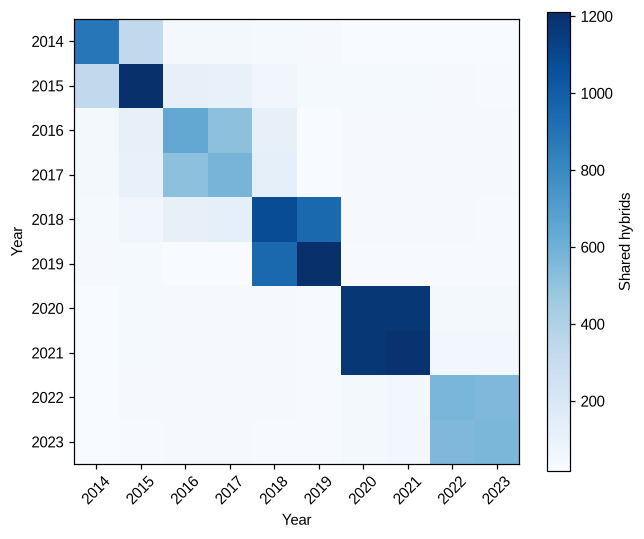

In [8]:
hybrid_sets = {y: set(ph.loc[ph.Year.eq(y), "Hybrid"].dropna()) for y in plot_years}
overlap = pd.DataFrame([[len(hybrid_sets[a] & hybrid_sets[b]) for b in plot_years]
                        for a in plot_years], index=plot_years, columns=plot_years)
overlap.to_csv(OUT / "hybrid_overlap.csv")
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(overlap, cmap="Blues")
ax.set_xticks(range(len(plot_years)), plot_years, rotation=45)
ax.set_yticks(range(len(plot_years)), plot_years)
ax.set(xlabel="Year", ylabel="Year")
fig.colorbar(image, ax=ax, label="Shared hybrids")
save_figure(fig, "hybrid_overlap")

## 4. Генотипная PCA: общие оси, панели годов
Один гибрид может быть в нескольких годах. Это описательная PCA всех сопоставленных гибридов; в моделях ниже её нет.

In [9]:
pca_ids = sorted(set(match.loc[match.has_observed_markers, "Hybrid"]))
if len(pca_ids) < 3:
    raise ValueError("Недостаточно сопоставленных гибридов для PCA.")
A = geno.loc[pca_ids].to_numpy()
prep_pca = prepare_markers(A, A[:0], coding="dosage")
scale = np.sqrt(2 * prep_pca["p"] * (1 - prep_pca["p"]))
Z = prep_pca["Z"] / scale
pca = PCA(n_components=2, svd_solver="randomized", random_state=SEED)
coordinates = pca.fit_transform(Z)
scores = pd.DataFrame(coordinates, index=pca_ids, columns=["PC1", "PC2"])
scores.index.name = "Hybrid"
scores.to_csv(OUT / "pca_scores.csv")
pca_year = match.loc[match.has_observed_markers, ["Year", "Hybrid"]].merge(
    scores.reset_index(), on="Hybrid", validate="many_to_one")
pca_year.to_csv(OUT / "pca_by_year.csv", index=False)
pd.Series(pca.explained_variance_ratio_, index=["PC1", "PC2"], name="fraction").to_csv(
    OUT / "pca_variance.csv")
print("PCA:", len(pca_ids), "гибридов;", prep_pca["n_markers"], "SNP")

PCA: 4940 гибридов; 2424 SNP


findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font f

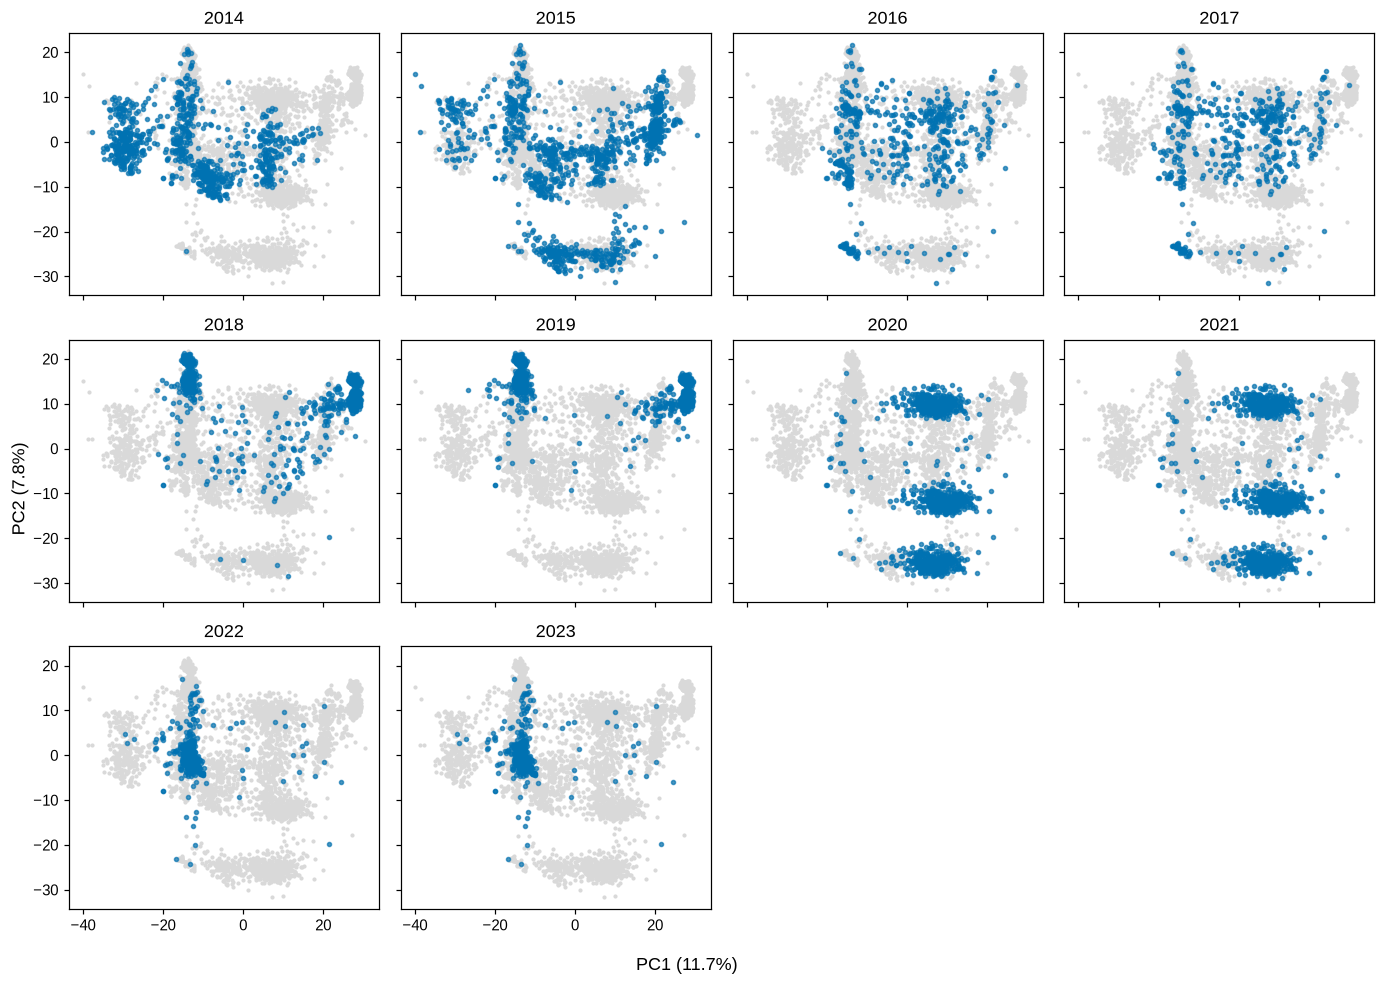

In [10]:
ncols = min(4, len(plot_years))
nrows = int(np.ceil(len(plot_years) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.2*ncols, 3*nrows),
                         sharex=True, sharey=True, squeeze=False)
for ax, year in zip(axes.flat, plot_years):
    part = pca_year.loc[pca_year.Year.eq(year)]
    ax.scatter(scores.PC1, scores.PC2, s=3, color="0.85", rasterized=True)
    ax.scatter(part.PC1, part.PC2, s=7, alpha=.65, color="#0072B2", rasterized=True)
    ax.set_title(str(year))
for ax in list(axes.flat)[len(plot_years):]:
    ax.set_visible(False)
fig.supxlabel(f"PC1 ({100*pca.explained_variance_ratio_[0]:.1f}%)")
fig.supylabel(f"PC2 ({100*pca.explained_variance_ratio_[1]:.1f}%)")
save_figure(fig, "pca_by_year")
del A, Z, prep_pca

## 5. Подготовка сравнения
Разделение по **Hybrid** внутри года. Повторности усредняются в Env×Hybrid. Среднее среды — только по train; скорректированный фенотип — средний остаток гибрида. Это простая поправка, не полевые BLUE/BLUP. Среды без train исключаются из оценки с явным учётом. Общие родители между train/test не запрещены.

In [11]:
if duplicate_rows.any():
    raise ValueError("Найдены повторные полные ключи делянок: проверьте duplicate_plot_keys.csv. "
                     "Автоматически удалять их нельзя.")
if not 0 < TRAIN_FRAC < 1 or N_REPEATS < 1:
    raise ValueError("Нужны 0 < TRAIN_FRAC < 1 и N_REPEATS >= 1.")
ph["model_eligible"] = (ph[["Year", "Env", "Hybrid", TARGET]].notna().all(axis=1)
                        & ph.Hybrid.isin(geno.index[geno.notna().any(axis=1)]))
eligibility = ph.groupby("Year").agg(n_all=("Hybrid", "size"),
                                    n_eligible=("model_eligible", "sum"))
eligibility["n_excluded"] = eligibility.n_all - eligibility.n_eligible
eligibility.to_csv(OUT / "model_eligibility.csv")
model_data = ph.loc[ph.model_eligible].copy()
env_hybrid = model_data.groupby(["Year", "Env", "Hybrid"], as_index=False)[TARGET].mean()
display(eligibility)

,n_all,n_eligible,n_excluded
Year,,,
2014,12675,11553,1122
2015,13688,13156,532
2016,15387,14108,1279
2017,15533,12446,3087
2018,20851,20182,669
2019,20806,19256,1550
2020,16940,16141,799
2021,20132,19563,569
2022,19084,18519,565


In [12]:
def adjust_split(frame, train_ids):
    """frame: один год, одна строка на Env×Hybrid."""
    in_train = frame.Hybrid.isin(train_ids)
    env_mean = frame.loc[in_train].groupby("Env", observed=True)[TARGET].mean().rename("env_mean")
    adjusted = frame.join(env_mean, on="Env", validate="many_to_one")
    unsupported = adjusted.loc[adjusted.env_mean.isna()].copy()
    adjusted = adjusted.loc[adjusted.env_mean.notna()].copy()
    adjusted["adjusted_y"] = adjusted[TARGET] - adjusted.env_mean
    train = adjusted.loc[adjusted.Hybrid.isin(train_ids)]
    test = adjusted.loc[~adjusted.Hybrid.isin(train_ids)]
    y_train = train.groupby("Hybrid", observed=True).adjusted_y.mean().sort_index()
    y_test = test.groupby("Hybrid", observed=True).adjusted_y.mean().sort_index()
    return y_train, y_test, test, unsupported, env_mean

In [13]:
def fit_two_models(y_train, X_train, X_test):
    """Каждый prep видит только свои train/test; test-фенотипы сюда не входят."""
    a = prepare_gblup(X_train, X_test, coding="dosage")
    f = gblup_fit_reml(y_train, a["K"], eigen=a["eigen"])
    yield "GBLUP", gblup_predict(f, a["cross"]), f, a["n_markers"]
    b = prepare_kblup(X_train, X_test, coding="dosage")
    f = kblup_fit(y_train, b)
    yield "KBLUP", kblup_predict(f, b), f, b["n_markers"]

## 6. Запуск по годам

In [14]:
metric_rows, prediction_rows, split_rows = [], [], []
unsupported_rows, env_rows, status_rows = [], [], []
for year in plot_years:
    frame = env_hybrid.loc[env_hybrid.Year.eq(year)].copy()
    ids = np.array(sorted(frame.Hybrid.unique()))
    for repeat, (tr, te) in enumerate(random_splits(len(ids), TRAIN_FRAC,
                                                   N_REPEATS, SEED + int(year)), 1):
        tag = dict(Year=int(year), repeat=repeat)
        if len(tr) < 3 or len(te) < 2:
            status_rows.append(dict(**tag, status="skipped", reason="Too few hybrids"))
            continue
        for group, ix in [("train", tr), ("test", te)]:
            split_rows.extend(dict(**tag, Hybrid=h, split=group) for h in ids[ix])
        ytr, yte, test, unsupported, env_mean = adjust_split(frame, ids[tr])
        unsupported_rows.append(unsupported.assign(**tag, reason="No train hybrids in Env"))
        env_rows.append(env_mean.reset_index().assign(**tag))
        status_rows.append(dict(**tag, status="prepared", n_train=len(ytr),
            n_test_requested=len(te), n_test_scored=len(yte),
            n_env_total=frame.Env.nunique(), n_env_supported=len(env_mean),
            n_test_env_hybrid=len(test), n_unsupported_env_hybrid=len(unsupported)))
        if len(yte) < 2 or np.ptp(ytr.to_numpy()) == 0:
            status_rows.append(dict(**tag, status="skipped", reason="No scorable test / constant train"))
            continue
        Xtr = geno.loc[ytr.index].to_numpy()
        Xte = geno.loc[yte.index].to_numpy()
        start = time.perf_counter()
        predictions = [("Env_mean", np.zeros(len(yte)), None, 0)]
        predictions.extend(fit_two_models(ytr.to_numpy(), Xtr, Xte))
        for name, pred, fit, n_markers in predictions:
            metrics = regression_metrics(yte.to_numpy(), pred)
            raw_pred = test.env_mean + test.Hybrid.map(pd.Series(pred, index=yte.index))
            raw_rmse = regression_metrics(test[TARGET].to_numpy(), raw_pred.to_numpy())["rmse"]
            vc = fit["vc"] if fit else {}
            metric_rows.append(dict(**tag, model=name, n_train=len(ytr), n_test=len(yte),
                n_markers=n_markers, **metrics, raw_rmse=raw_rmse,
                lam=vc.get("lam", np.nan), converged=vc.get("converged", True),
                at_boundary=vc.get("at_boundary", False)))
            prediction_rows.append(pd.DataFrame({"Hybrid": yte.index, "observed": yte.to_numpy(),
                "predicted": pred}).assign(**tag, model=name))
        print(year, repeat, f"train={len(ytr)}, test={len(yte)}, {time.perf_counter()-start:.1f} s")

2014 1 train=595, test=255, 2.7 s
2015 1 train=804, test=345, 2.4 s
2016 1 train=389, test=167, 0.7 s
2017 1 train=342, test=146, 0.4 s
2018 1 train=727, test=312, 1.8 s
2019 1 train=811, test=347, 1.2 s
2020 1 train=822, test=353, 0.9 s
2021 1 train=826, test=354, 1.4 s
2022 1 train=384, test=165, 0.3 s
2023 1 train=382, test=164, 0.3 s


## 7. Метрики и файлы
`r`, `RMSE`, `MAE`, `R²` — по test-гибридам на скорректированной урожайности (Mg/ha). `raw_rmse` — по test Env×Hybrid после добавления train-среднего Env. `Env_mean` — baseline без генетики. Отрицательный R² допустим; константный прогноз даёт r=NA. Один split — предварительный результат, не доверительный интервал.

In [15]:
metrics_by_year = pd.DataFrame(metric_rows)
metrics_by_year.to_csv(OUT / "metrics_by_year.csv", index=False)
pd.DataFrame(split_rows).to_csv(OUT / "split_assignments.csv", index=False)
pd.DataFrame(status_rows).to_csv(OUT / "split_status.csv", index=False)
def concat_or_empty(frames):
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
concat_or_empty(prediction_rows).to_csv(OUT / "holdout_predictions.csv", index=False)
concat_or_empty(unsupported_rows).to_csv(OUT / "unsupported_env_hybrid.csv", index=False)
concat_or_empty(env_rows).to_csv(OUT / "train_env_means.csv", index=False)
config = dict(years=YEARS, seed=SEED, train_frac=TRAIN_FRAC, n_repeats=N_REPEATS,
              target=TARGET, phenotype_file=str(PHENO_FILE), genotype_file=str(GENO_FILE),
              numpy=np.__version__, pandas=pd.__version__, python=sys.version)
(OUT / "run_config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
if metrics_by_year.empty:
    display(pd.DataFrame(status_rows))
    raise ValueError("Нет оценённых разбиений: смотрите split_status.csv.")
display(metrics_by_year.round(3))
display(metrics_by_year.groupby("model")[["converged", "at_boundary"]].sum())

,Year,repeat,model,n_train,n_test,n_markers,r,rmse,mae,r2,raw_rmse,lam,converged,at_boundary
0,2014,1,Env_mean,595,255,0,NaN,1.095,0.836,-0.000,1.736,NaN,True,False
1,2014,1,GBLUP,595,255,2416,0.469,0.968,0.734,0.218,1.641,1.445,True,False
2,2014,1,KBLUP,595,255,2416,0.611,0.868,0.644,0.371,1.583,0.638,True,False
3,2015,1,Env_mean,804,345,0,NaN,1.186,0.922,-0.000,1.865,NaN,True,False
4,2015,1,GBLUP,804,345,2423,0.518,1.016,0.780,0.266,1.757,0.692,True,False
5,2015,1,KBLUP,804,345,2423,0.620,0.936,0.710,0.378,1.706,0.233,True,False
6,2016,1,Env_mean,389,167,0,NaN,1.071,0.847,-0.036,1.740,NaN,True,False
7,2016,1,GBLUP,389,167,2423,0.717,0.741,0.549,0.505,1.553,0.223,True,False
8,2016,1,KBLUP,389,167,2423,0.745,0.724,0.552,0.527,1.548,0.212,True,False
9,2017,1,Env_mean,342,146,0,NaN,1.126,0.868,-0.008,1.732,NaN,True,False


,converged,at_boundary
model,,
Env_mean,10,0
GBLUP,10,0
KBLUP,10,0


findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font family 'Arimo' not found.
findfont: Font f

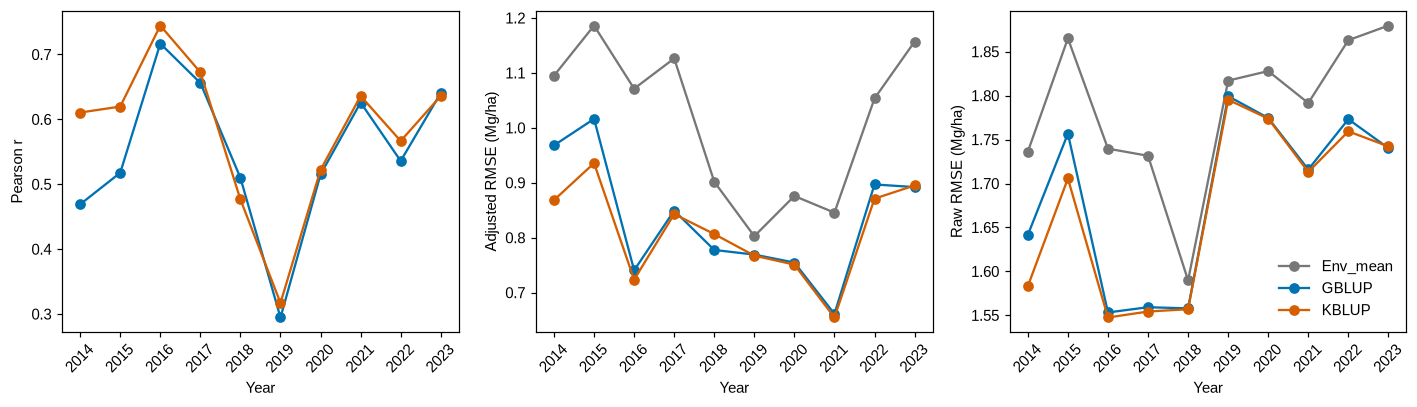

Таблицы: /mnt/c/Users/User/Desktop/Генотек/Biomni_lab_downloads_20261010_090451/gp_models/results/g2f_08_v3
Графики: /mnt/c/Users/User/Desktop/Генотек/Biomni_lab_downloads_20261010_090451/gp_models/figures/g2f_08_v3


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
colors = {"GBLUP": "#0072B2", "KBLUP": "#D55E00", "Env_mean": "#777777"}
for ax, metric, label in zip(axes, ["r", "rmse", "raw_rmse"],
                            ["Pearson r", "Adjusted RMSE (Mg/ha)", "Raw RMSE (Mg/ha)"]):
    for name, group in metrics_by_year.groupby("model"):
        summary = group.groupby("Year")[metric].mean()
        ax.plot(summary.index, summary, marker="o", label=name, color=colors[name])
    ax.set(xlabel="Year", ylabel=label, xticks=plot_years)
    ax.tick_params(axis="x", rotation=45)
axes[-1].legend(frameon=False)
save_figure(fig, "model_metrics_by_year")
print("Таблицы:", OUT)
print("Графики:", FIG)

Для обсуждения пришлите `year_summary.csv`, `hybrid_matching.csv`, `model_eligibility.csv`, `split_status.csv`, `metrics_by_year.csv` и рисунки `pca_by_year.png`, `model_metrics_by_year.png`. Сначала смотрим покрытие, исключения, baseline и устойчивость по годам; затем решаем, нужны ли повторы, IBS или более строгая поправка на дизайн.